# Wildfire Risk Heatmaps

Daily wildfire risk maps of Castilla y León for the last year of the dataset, with the real fires on top.

The model is trained with balanced classes, so its outputs rank the risk but are not real probabilities. That is why the maps show the **relative risk**: the percentile of each point among all the points of the region on that day.

## Libraries

In [1]:
import xarray as xr # Climate data
import pandas as pd # CSV and dataframes
import geopandas as gpd # Geographical data and spatial joins
import numpy as np
import lightgbm as lgb # Saved model loading
import matplotlib.pyplot as plt

from os import listdir
from lightgbm import LGBMClassifier
from matplotlib.colors import LinearSegmentedColormap # Color ramp of the maps
from matplotlib.ticker import PercentFormatter # Axes in %
from scipy.spatial import cKDTree # Nearest grid point of each fire
from scipy.stats import rankdata # Percentile of each point within its day
from sklearn.metrics import roc_auc_score

## Data Loading And Configuration

In [2]:
full_df = pd.read_csv("./dataset.csv")
full_df["date"] = pd.to_datetime(full_df["date"], format="%Y-%m-%d")

In [3]:
FEATURES = [c for c in full_df.columns if c not in ["date", "longitude", "latitude", "fire"]] # Same variables as in training

MAP_YEAR = 2023 # Year shown in the maps (the last one in the dataset)
GRID_RES = 0.03 # Grid resolution in degrees (about 3 km), smaller values give finer maps but take longer

NEG_POS_RATIO = (full_df["fire"] == 0).sum() / (full_df["fire"] == 1).sum() # Used to balance the classes

# Same bounding box as in the preprocessing (it affects the terrain derivatives at the borders)
fires = full_df[full_df["fire"] == 1]
min_lon, max_lon = fires["longitude"].min(), fires["longitude"].max()
min_lat, max_lat = fires["latitude"].min(), fires["latitude"].max()

# Colors used in every plot
RISK_CMAP = LinearSegmentedColormap.from_list("risk", ["#cde2fb", "#3987e5", "#0d366b"]) # Light = low risk, dark = high risk
FIRE_COLOR = "#eb6834"
RANDOM_COLOR = "#b0b0b0"
STATIC_COLOR = "#0d366b"
DAILY_COLOR = "#2a78d6"

## Model
---
Same hyperparameters as the tuned model of `bestmodel.ipynb`, but trained only with data before the map year (with the 90 days embargo), so the maps are a real forecast. The saved model is only loaded to check that both use the same variables.

In [4]:
# Tuned hyperparameters (from bestmodel.ipynb)
TUNED_PARAMS = {
    "n_estimators": 1700,
    "learning_rate": 0.0051,
    "num_leaves": 213,
    "min_child_samples": 17,
    "subsample": 0.9805,
    "colsample_bytree": 0.3040,
    "reg_alpha": 0.0033,
    "reg_lambda": 0.0030,
    "scale_pos_weight": NEG_POS_RATIO,
    "subsample_freq": 1,
    "random_state": 42,
    "n_jobs": -1,
    "verbose": -1,
}

assert lgb.Booster(model_file="best_model.txt").feature_name() == FEATURES, "The saved model uses different variables"

train_rows = full_df["date"] <= pd.Timestamp(f"{MAP_YEAR}-01-01") - pd.Timedelta(days=90) # Before the map year, minus the embargo
test_rows = full_df["date"].dt.year == MAP_YEAR

model = LGBMClassifier(**TUNED_PARAMS)
model.fit(full_df.loc[train_rows, FEATURES], full_df.loc[train_rows, "fire"])

# Score on the dataset records of the map year
proba = model.predict_proba(full_df.loc[test_rows, FEATURES])[:, 1]
print(f"ROC-AUC on {MAP_YEAR}: {roc_auc_score(full_df.loc[test_rows, 'fire'], proba):.3f}")

ROC-AUC on 2023: 0.780


## Grid
---
A regular grid covers the region. Each point gets the same static variables as the dataset, computed as in `preprocessing.ipynb`.

In [5]:
region = gpd.read_file("data/cyl.geojson").to_crs("EPSG:4326") # Region border, used for the grid limits and the maps

# Regular grid of points over the bounding box of the region
x0, y0, x1, y1 = region.total_bounds
grid_lons = np.arange(x0, x1 + GRID_RES, GRID_RES)
grid_lats = np.arange(y0, y1 + GRID_RES, GRID_RES)
lon2d, lat2d = np.meshgrid(grid_lons, grid_lats)
rows2d, cols2d = np.indices(lon2d.shape) # Position of each point in the 2D grid, used to draw the maps

cells = gpd.GeoDataFrame(
    {"row": rows2d.ravel(), "col": cols2d.ravel(), "longitude": lon2d.ravel(), "latitude": lat2d.ravel()},
    geometry=gpd.points_from_xy(lon2d.ravel(), lat2d.ravel()),
    crs="EPSG:4326",
)

#### Vegetation
The categorical variables are mapped by a risk score, as in the preprocessing.

In [6]:
mfe = gpd.read_file("data/mfe_cyl/MFE_41.shp")

numeric_vars_mfe = ["FCCHER", "FCCTOT", "HMMAT", "O1", "O2", "O3", "FCCARB", "FCCMAT"]
categorical_vars_mfe = [
    "TipesTR25", "Especie1", "Especie2", "Especie3", "Estado1", "Estado2",
    "Estado3", "Distribuci", "TIPOBOSQUE", "n_MODCOM", "n_REGBIO",
]
mfe = mfe[numeric_vars_mfe + categorical_vars_mfe + ["geometry"]] # Drop auxiliary columns

mapa_riesgo_especies = {
    "sin datos": 0,
    "Salix spp.": 1, "Salix atrocinerea": 1, "Salix alba": 1, "Salix fragilis": 1,
    "Salix caprea": 1, "Salix elaeagnos": 1, "Salix purpurea": 1, "Salix babylonica": 1,
    "Alnus glutinosa": 1, "Populus x canadensis": 1, "Populus nigra": 1, "Populus alba": 1,
    "Populus tremula": 1, "Fraxinus angustifolia": 1, "Fraxinus excelsior": 1, "Fraxinus ornus": 1,
    "Ulmus minor": 1, "Ulmus glabra": 1, "Ulmus pumila": 1, "Tamarix spp.": 1,
    "Sambucus nigra": 1, "Platanus hispanica": 1,
    "Fagus sylvatica": 2, "Ficus carica": 2, "Quercus pyrenaica": 2, "Quercus faginea": 2,
    "Quercus petraea": 2, "Quercus humilis (Q. Pubescens)": 2, "Quercus canariensis": 2,
    "Quercus robur": 2, "Quercus rubra": 2, "Castanea sativa": 2, "Betula alba": 2,
    "Betula spp.": 2, "Betula pendula": 2, "Acer campestre": 2, "Acer monspessulanum": 2,
    "Acer pseudoplatanus": 2, "Acer negundo": 2, "Acer opalus": 2, "Acer spp.": 2,
    "Sorbus aucuparia": 2, "Sorbus aria": 2, "Sorbus spp.": 2, "Sorbus torminalis": 2,
    "Prunus spp.": 2, "Prunus avium": 2, "Prunus padus": 2, "Corylus avellana": 2,
    "Juglans regia": 2, "Juglans nigra": 2, "Crataegus monogyna": 2, "Crataegus spp.": 2,
    "Celtis australis": 2, "Tilia spp.": 2, "Tilia platyphyllos": 2, "Tilia cordata": 2,
    "Pyrus spp.": 2, "Malus sylvestris": 2, "Robinia pseudoacacia": 2, "Ailanthus altissima": 2,
    "Carpinus betulus": 2, "Gleditsia triacanthos": 2, "Mezcla de pequeñas frondosas": 2,
    "Mezcla de frondosas de gran porte": 2, "Otras frondosas": 2,
    "Quercus ilex": 3, "Quercus suber": 3, "Prunus lusitanica": 3, "Ilex aquifolium": 3,
    "Juniperus thurifera": 3, "Juniperus communis": 3, "Juniperus oxycedrus": 3,
    "Juniperus phoenicea": 3, "Arbutus unedo": 3, "Phillyrea latifolia": 3,
    "Olea europaea": 3, "Taxus baccata": 3,
    "Pinus pinea": 4, "Pinus nigra": 4, "Pinus sylvestris": 4, "Pinus uncinata": 4,
    "Otra Coniferas": 4, "Mezcla de coníferas": 4, "Cupressus arizonica": 4,
    "Cupressus sempervirens": 4, "Cupressus macrocarpa": 4, "Pseudotsuga menziesii": 4,
    "Picea abies": 4, "Abies alba": 4, "Abies pinsapo": 4, "Thuja spp": 4,
    "Cedrus atlantica": 4, "Cedrus deodara": 4, "Chamaecyparis lawsoniana": 4,
    "Larix decidua": 4, "Larix spp.": 4, "Larix x eurolepis": 4,
    "Eucalyptus camaldulensis": 5, "Eucalyptus globulus": 5, "Eucalyptus nitens": 5,
    "Pinus halepensis": 5, "Pinus pinaster": 5, "Pinus radiata": 5,
    "Pinus canariensis": 5, "Acacia spp.": 5,
}
mapa_estado_ordinal = {"Sin datos": 0, "Fustal": 1, "Repoblado": 2, "Latizal": 3, "Monte bravo": 4}
mapa_distribucion = {
    "No procede": 0, "Piés aislados": 1, "Discontinua en bosquetes": 2, "Discontinua en fajas": 3,
    "Discontinua en mosaico": 4, "Discontinua irregular": 5, "Uniforme": 6,
}

# Fuel risk of the three main species, weighted by the occupation of each one
r1, r2, r3 = (mfe[f"Especie{i}"].map(mapa_riesgo_especies).fillna(0) for i in [1, 2, 3])
o1, o2, o3 = (mfe[f"O{i}"].fillna(0) for i in [1, 2, 3])
total_ocupacion = o1 + o2 + o3

mfe["Riesgo_Combustible"] = np.where(total_ocupacion > 0, (r1 * o1 + r2 * o2 + r3 * o3) / total_ocupacion, 0)
mfe["Estado1_num"] = mfe["Estado1"].map(mapa_estado_ordinal).fillna(0)
mfe["Distribuci_num"] = mfe["Distribuci"].map(mapa_distribucion).fillna(0)

mfe = pd.get_dummies(mfe, columns=["TIPOBOSQUE"], prefix="tipo_bosque", dtype=int) # One column per forest type
mfe = mfe.drop(columns=["Especie1", "Especie2", "Especie3", "O1", "O2", "O3", "Estado1", "Estado2", "Estado3", "Distribuci"]) # Already mapped
mfe = mfe.to_crs("EPSG:4326")

#### Population
Census of the map year, joined through the municipality of each point.

In [7]:
dem_df = pd.concat(
    [pd.read_csv("./data/provincias/" + f, sep=";", encoding="latin-1", thousands=".") for f in listdir("./data/provincias")], # Thousands="." is needed because of the data format
    ignore_index=True,
)
dem_df = pd.DataFrame({
    "INE": dem_df["Municipios"].str[:5],
    "Year": dem_df["Periodo"].astype(int),
    "Population": pd.to_numeric(dem_df["Total"].astype(str).str.replace(".", "", regex=False), errors="coerce"),
})
dem_df = dem_df[dem_df["Year"] == MAP_YEAR].drop(columns="Year") # Only the map year is needed

munis = gpd.read_file("./data/municipios/recintos_municipales_inspire_peninbal_etrs89.shp")
munis["INE"] = munis["NATCODE"].str[-5:] # The INE code corresponds to [-5:] of "NATCODE" column
munis = munis[["INE", "geometry"]].to_crs(cells.crs)

#### Terrain

In [8]:
elevation_ds = xr.open_dataset("data/elev_ens_0.1deg_reg_v33.0e.nc")
elevation_ds = elevation_ds.sel(longitude=slice(min_lon, max_lon), latitude=slice(min_lat, max_lat)).load()

# Elevation derivatives
dz_dx = elevation_ds["elevation"].differentiate("longitude")
dz_dy = elevation_ds["elevation"].differentiate("latitude")
elevation_ds["slope"] = np.arctan(np.sqrt(dz_dx**2 + dz_dy**2))
elevation_ds["aspect_south"] = np.cos(np.arctan2(-dz_dy, dz_dx))

#### Data Merging
Points outside the Forest Map are dropped, the same rule used for the negatives of the dataset.

In [9]:
cells = gpd.sjoin(cells, mfe, how="inner", predicate="within").drop(columns="index_right") # Points outside the Forest Map are dropped
cells = gpd.sjoin(cells, munis, how="left", predicate="within").drop(columns="index_right")
cells = cells[~cells.index.duplicated()] # A point on the border of two polygons only keeps one

cells = cells.merge(dem_df, on="INE", how="left")
cells.loc[cells["INE"].str.startswith("53", na=False), "Population"] = 0 # This INE code usually means no population

# Coordinates of every point, used to select the nearest terrain and weather cell
lon = xr.DataArray(cells["longitude"].values, dims="cell")
lat = xr.DataArray(cells["latitude"].values, dims="cell")

# Join with elevation data
sampled_elev = elevation_ds[["elevation", "slope", "aspect_south"]].sel(longitude=lon, latitude=lat, method="nearest")
for var in sampled_elev.data_vars:
    cells[var] = sampled_elev[var].values

# Same names as in the dataset
cells = cells.rename(columns={
    "Population": "population",
    "FCCHER": "herbaceous_cover",
    "FCCTOT": "total_cover",
    "HMMAT": "shrub_height",
    "FCCARB": "tree_cover",
    "FCCMAT": "shrub_cover",
    "TipesTR25": "structure_type",
    "n_MODCOM": "fuel_model",
    "n_REGBIO": "biogeographic_region",
    "Riesgo_Combustible": "species_fuel_risk",
    "Estado1_num": "development_stage",
    "Distribuci_num": "stand_distribution",
    "tipo_bosque_-": "forest_type_none",
    "tipo_bosque_Coníferas": "forest_type_conifer",
    "tipo_bosque_Frondosas": "forest_type_broadleaf",
    "tipo_bosque_Masas mixtas": "forest_type_mixed",
})

print(f"Grid points: {len(cells)}")

Grid points: 11350


## Weather Of The Map Year
---
Same variables as in `preprocessing.ipynb`. One extra year is loaded before the map year, so the rolling windows and the consecutive dry days are complete from the 1st of January.

In [10]:
start_time = pd.Timestamp(f"{MAP_YEAR}-01-01") - pd.Timedelta(days=365) # One extra year for the rolling windows and the dry days
end_time = pd.Timestamp(f"{MAP_YEAR}-12-31")

# The 8 weather variables in a single dataset
# float64 -> float32 to avoid RAM overload, and .load() avoids using dask
climate_ds = xr.merge(
    [
        xr.open_dataset(f"data/{var}_ens_mean_0.1deg_reg_v33.0e.nc")
        .sel(time=slice(start_time, end_time), longitude=slice(min_lon, max_lon), latitude=slice(min_lat, max_lat))
        for var in ["rr", "hu", "tx", "tn", "tg", "qq", "fg", "pp"]
    ],
    join="override",
).astype(np.float32).load()

# Rolling statistics: name -> (variable, days, statistic)
rolling = {
    "rr_7d_sum": ("rr", 7, "sum"),
    "rr_30d_sum": ("rr", 30, "sum"),
    "rr_90d_sum": ("rr", 90, "sum"),
    "hu_7d_mean": ("hu", 7, "mean"),
    "hu_30d_mean": ("hu", 30, "mean"),
    "tx_3d_max": ("tx", 3, "max"),
    "tx_7d_mean": ("tx", 7, "mean"),
    "tn_3d_min": ("tn", 3, "min"),
    "tn_7d_mean": ("tn", 7, "mean"),
    "tn_14d_mean": ("tn", 14, "mean"),
    "tn_30d_mean": ("tn", 30, "mean"),
    "qq_7d_sum": ("qq", 7, "sum"),
    "qq_30d_sum": ("qq", 30, "sum"),
    "fg_3d_max": ("fg", 3, "max"),
    "fg_30d_max": ("fg", 30, "max"),
}
for name, (var, days, stat) in rolling.items():
    climate_ds[name] = getattr(climate_ds[var].rolling(time=days, min_periods=1), stat)()

# Climate derivatives
climate_ds["wind_dryness_ratio"] = climate_ds["fg"] / (climate_ds["hu"] + 1e-5)
climate_ds["fanning_index"] = climate_ds["fg"] * (100 - climate_ds["hu"]) * climate_ds["tx"]
climate_ds["moisture_deficit_30d"] = (climate_ds["qq_30d_sum"] * climate_ds["tx_7d_mean"]) / (climate_ds["rr_30d_sum"] + 1)

# Consecutive dry days (less than 1 mm of rain): total dry days minus the total at the last rainy day
is_dry = (climate_ds["rr"] < 1.0).astype(np.int32)
climate_ds["cdd"] = is_dry.cumsum(dim="time") - is_dry.cumsum(dim="time").where(is_dry == 0).ffill(dim="time").fillna(0)

climate_ds = climate_ds.sel(time=slice(f"{MAP_YEAR}-01-01", end_time)) # Only the map year from here on

# Day of year encoding
day = climate_ds["time"].dt.dayofyear
climate_ds["day_sin"] = np.sin(2 * np.pi * day / 365.25).astype(np.float32)
climate_ds["day_cos"] = np.cos(2 * np.pi * day / 365.25).astype(np.float32)

# Same names as in the dataset
climate_ds = climate_ds.rename({
    "rr": "precipitation",
    "rr_7d_sum": "precipitation_7d_sum",
    "rr_30d_sum": "precipitation_30d_sum",
    "rr_90d_sum": "precipitation_90d_sum",
    "hu": "humidity",
    "hu_7d_mean": "humidity_7d_mean",
    "hu_30d_mean": "humidity_30d_mean",
    "tx": "max_temperature",
    "tx_3d_max": "max_temperature_3d_max",
    "tx_7d_mean": "max_temperature_7d_mean",
    "tn": "min_temperature",
    "tn_3d_min": "min_temperature_3d_min",
    "tn_7d_mean": "min_temperature_7d_mean",
    "tn_14d_mean": "min_temperature_14d_mean",
    "tn_30d_mean": "min_temperature_30d_mean",
    "tg": "mean_temperature",
    "qq": "radiation",
    "qq_7d_sum": "radiation_7d_sum",
    "qq_30d_sum": "radiation_30d_sum",
    "fg": "wind_speed",
    "fg_3d_max": "wind_speed_3d_max",
    "fg_30d_max": "wind_speed_30d_max",
    "pp": "sea_level_pressure",
    "cdd": "consecutive_dry_days",
})

days = pd.DatetimeIndex(climate_ds["time"].values)
print(f"Days in {MAP_YEAR}: {len(days)} ({days.min().date()} to {days.max().date()})")

Days in 2023: 365 (2023-01-01 to 2023-12-31)


## Daily Risk
---
Every grid point is scored on every day of the year, with the weather of its nearest weather cell. The scores are turned into percentiles within the day: 1 is the riskiest point of the region that day and 0 the safest.

In [11]:
risk = np.empty((len(days), len(cells)), dtype=np.float32) # Score of every point (columns) on every day (rows)

for t in range(len(days)):
    weather = climate_ds.isel(time=t).sel(longitude=lon, latitude=lat, method="nearest") # Weather of every point that day
    X = cells.assign(**{var: weather[var].values for var in weather.data_vars}) # Static + weather variables
    risk[t] = model.predict_proba(X[FEATURES])[:, 1]

risk_pct = rankdata(risk, axis=1) / len(cells) # Percentile of each point within its day
mean_pct = risk_pct.mean(axis=0) # Mean relative risk over the year

## Fires In The Riskiest Areas
---
Each fire of the map year is placed in its nearest grid point and checked against the risk of that day. Two maps are compared:
- **Daily map**: risk of the day of each fire.
- **Static map**: mean risk of the year, it only shows where fires usually happen.

A random map would place 10% of the fires in the riskiest 10% of the region.

In [12]:
fires_year = fires[fires["date"].dt.year == MAP_YEAR].copy()

_, cell = cKDTree(cells[["longitude", "latitude"]]).query(fires_year[["longitude", "latitude"]]) # Nearest grid point of each fire
fires_year["daily_pct"] = risk_pct[fires_year["date"].dt.dayofyear - 1, cell] # Risk of that point on the day of the fire
fires_year["static_pct"] = (rankdata(mean_pct) / len(cells))[cell] # Position of that point in the mean risk ranking

# Share of the fires that fall in the riskiest X% of the region, for every X from 0% to 100%
shares = np.arange(101) / 100
captured = pd.DataFrame({
    "Random": shares,
    "Static map": [(fires_year["static_pct"] > 1 - s).mean() for s in shares],
    "Daily map": [(fires_year["daily_pct"] > 1 - s).mean() for s in shares],
}, index=shares)

print(f"Fires in {MAP_YEAR}: {len(fires_year)}")
captured.loc[[0.1, 0.2]].round(2) # Riskiest 10% and 20% of the region

Fires in 2023: 928


,Random,Static map,Daily map
0.1,0.1,0.28,0.33
0.2,0.2,0.43,0.50


#### Fires Captured By The Riskiest Areas
The higher the curve over the diagonal, the more fires fall in a small part of the region.

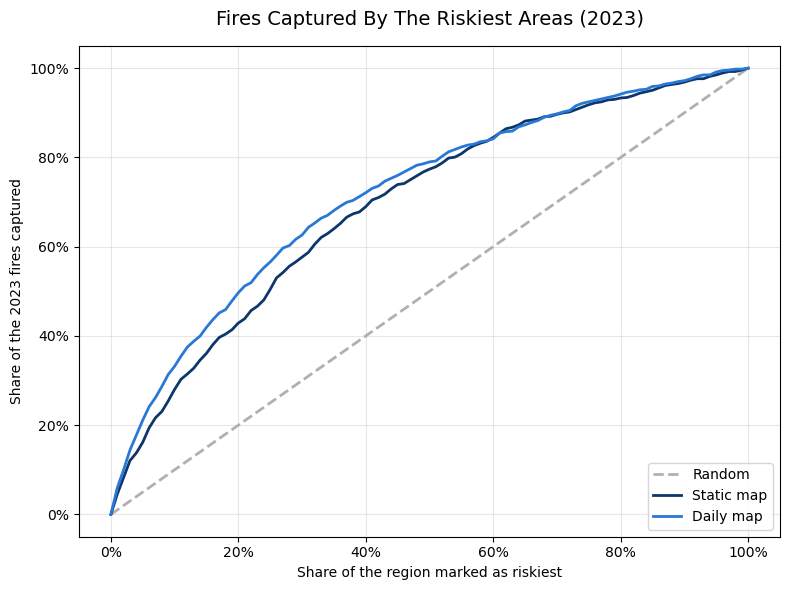

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, color, ls in [("Random", RANDOM_COLOR, "--"), ("Static map", STATIC_COLOR, "-"), ("Daily map", DAILY_COLOR, "-")]:
    ax.plot(shares, captured[name], color=color, ls=ls, lw=2, label=name)

ax.set_xlabel("Share of the region marked as riskiest")
ax.set_ylabel(f"Share of the {MAP_YEAR} fires captured")
ax.set_title(f"Fires Captured By The Riskiest Areas ({MAP_YEAR})", fontsize=14, pad=15)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("images/heatmap_capture.png", dpi=150)
plt.show()

## Maps
---
Light points are the safest of the region and dark points the riskiest. The fires are drawn in orange.

In [14]:
# Draws the risk of every grid point, the region border and the fires
def draw_map(ax, values, title, fires, marker_size):
    grid = np.full(lon2d.shape, np.nan) # Points outside the region stay empty
    grid[cells["row"], cells["col"]] = values

    mesh = ax.pcolormesh(grid_lons, grid_lats, grid, cmap=RISK_CMAP, vmin=0, vmax=1, shading="nearest")
    region.boundary.plot(ax=ax, color="#4a4a4a", lw=0.8)
    ax.scatter(fires["longitude"], fires["latitude"], s=marker_size, color=FIRE_COLOR, edgecolors="white", linewidths=0.8, label="Fire")

    ax.set_aspect(1 / np.cos(np.deg2rad(41.5))) # Keeps the shape of the region in longitude / latitude
    ax.set_axis_off()
    ax.set_title(title, fontsize=12, pad=10)
    ax.legend(loc="lower right")
    return mesh

#### Mean Risk Of The Year
Mean of the daily percentiles of each point, with every fire of the year.

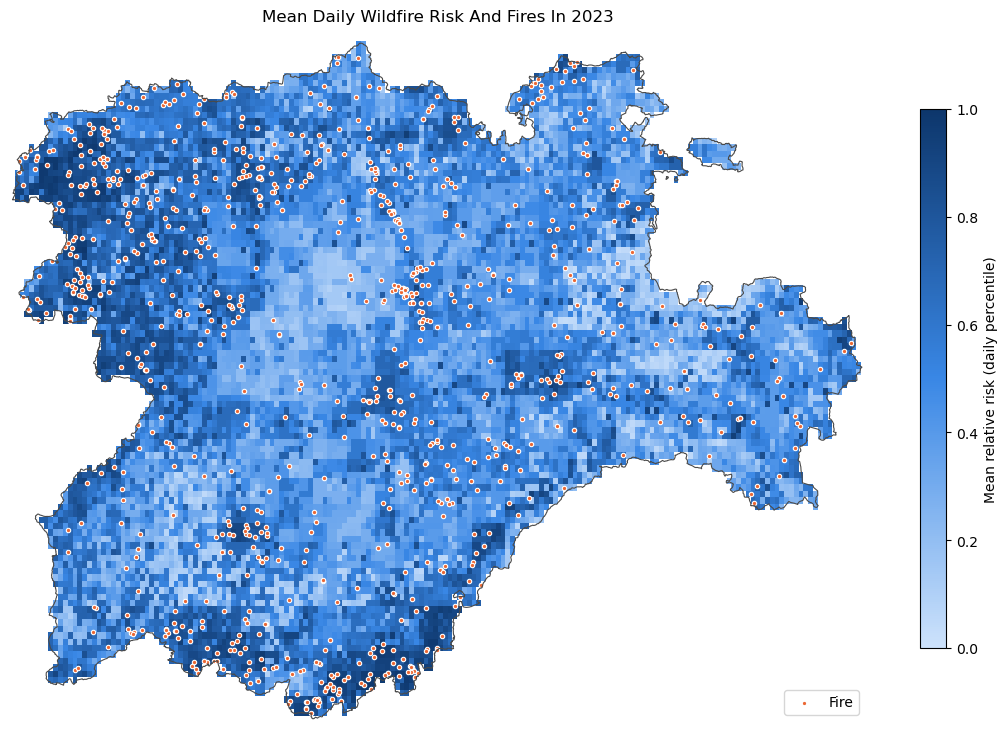

In [15]:
fig, ax = plt.subplots(figsize=(11, 8))

mesh = draw_map(ax, mean_pct, f"Mean Daily Wildfire Risk And Fires In {MAP_YEAR}", fires_year, marker_size=10)
fig.colorbar(mesh, ax=ax, shrink=0.7, label="Mean relative risk (daily percentile)")

plt.tight_layout()
plt.savefig("images/heatmap_year.png", dpi=150)
plt.show()

#### Days With The Most Fires
Risk map of the four days with the most fires, each one with only the fires of that day.

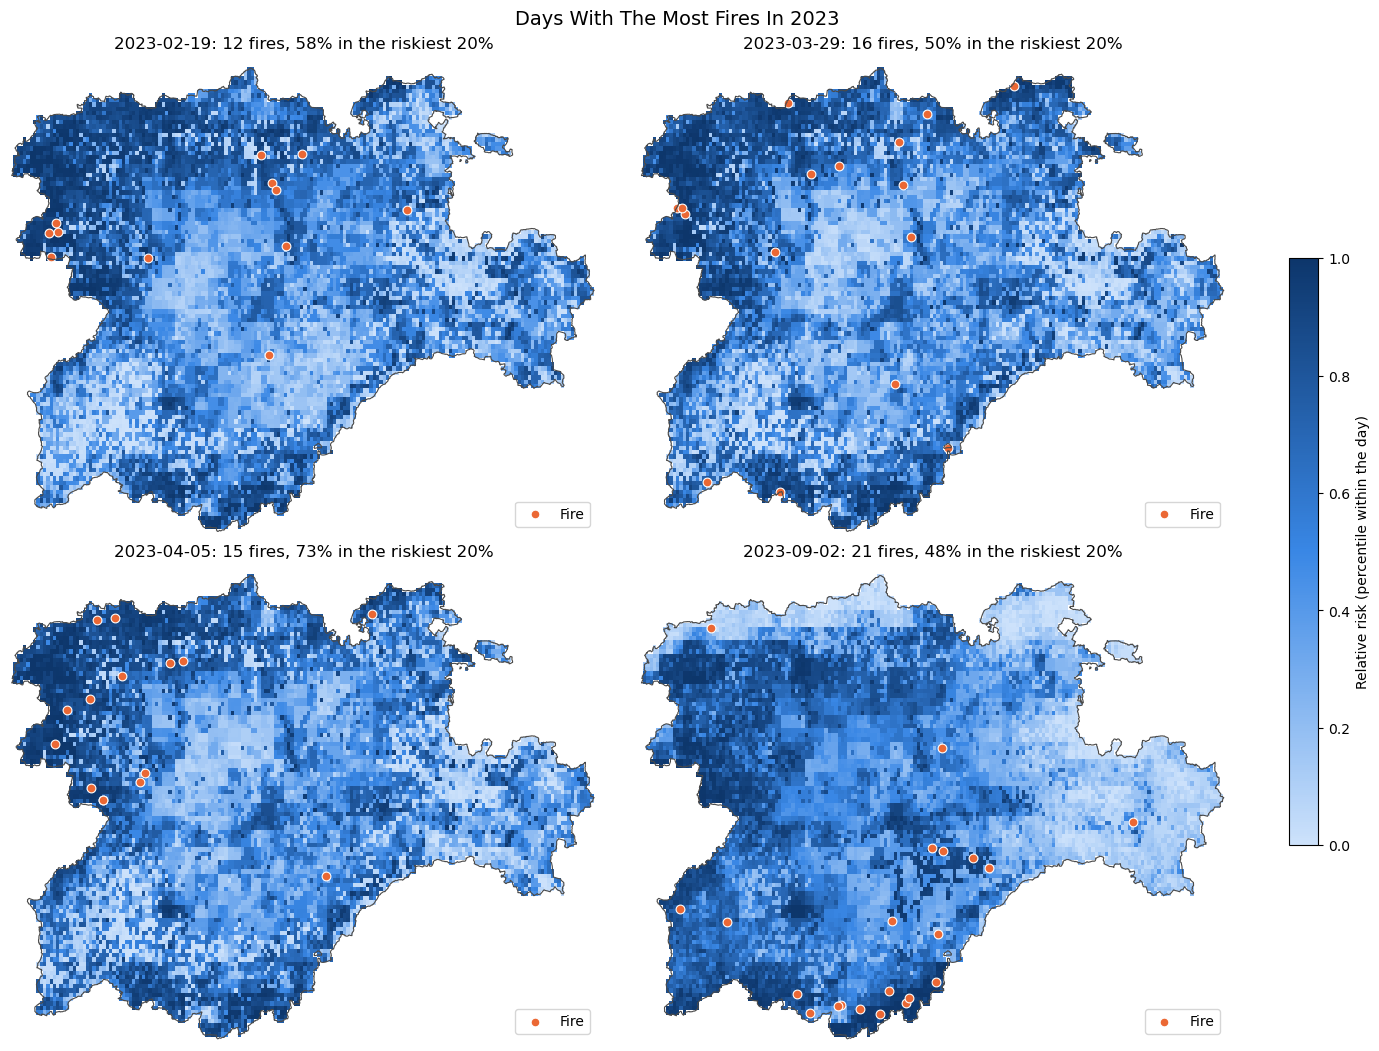

In [16]:
top_days = fires_year["date"].value_counts().head(4).index.sort_values() # In chronological order

fig, axes = plt.subplots(2, 2, figsize=(14, 10.4), layout="constrained")

for ax, day in zip(axes.flat, top_days):
    day_fires = fires_year[fires_year["date"] == day]
    in_top = (day_fires["daily_pct"] > 0.8).mean() # Share of the fires in the riskiest 20%
    title = f"{day.date()}: {len(day_fires)} fires, {in_top:.0%} in the riskiest 20%"
    mesh = draw_map(ax, risk_pct[day.dayofyear - 1], title, day_fires, marker_size=40)

fig.colorbar(mesh, ax=axes, shrink=0.6, label="Relative risk (percentile within the day)")
fig.suptitle(f"Days With The Most Fires In {MAP_YEAR}", fontsize=14)

plt.savefig("images/heatmap_days.png", dpi=150, bbox_inches="tight")
plt.show()